In [28]:

# Step 1: Import Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

import joblib
import warnings
warnings.filterwarnings("ignore")

print("All libraries imported successfully!")


All libraries imported successfully!


In [25]:

# Step 2: Load Dataset

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("heart_disease_augmented_practice.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Saving heart_disease_augmented_practice.csv to heart_disease_augmented_practice (2).csv
Dataset loaded successfully!
Dataset shape: (3030, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,65.0,1,0,128.0,235.0,0,1,101.0,1,0.319263,1,1.0,3.0,1
1,58.0,1,0,128.0,259.0,0,0,130.0,1,3.000000,1,2.0,3.0,0
2,NaN,1,1,155.0,215.0,0,0,160.0,0,0.512287,2,1.0,2.0,0
3,40.0,1,0,110.0,167.0,0,0,114.0,1,2.000000,1,0.0,3.0,0
4,61.0,1,0,120.0,260.0,0,1,140.0,1,3.600000,1,1.0,3.0,0


In [26]:

# Step 3: Dataset Exploration

# Display first five rows
print("First 5 Rows:")
display(df.head())

# Display dataset dimensions
print("\nDataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()

# Display statistical summary
print("\nStatistical Summary:")
display(df.describe())

# Display target distribution
print("\nTarget Distribution:")
print(df["target"].value_counts())


First 5 Rows:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,65.0,1,0,128.0,235.0,0,1,101.0,1,0.319263,1,1.0,3.0,1
1,58.0,1,0,128.0,259.0,0,0,130.0,1,3.000000,1,2.0,3.0,0
2,NaN,1,1,155.0,215.0,0,0,160.0,0,0.512287,2,1.0,2.0,0
3,40.0,1,0,110.0,167.0,0,0,114.0,1,2.000000,1,0.0,3.0,0
4,61.0,1,0,120.0,260.0,0,1,140.0,1,3.600000,1,1.0,3.0,0



Dataset Shape: (3030, 14)

Column Names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3030 entries, 0 to 3029
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       2943 non-null   float64
 1   sex       3030 non-null   int64  
 2   cp        3030 non-null   int64  
 3   trestbps  2952 non-null   float64
 4   chol      2943 non-null   float64
 5   fbs       3030 non-null   int64  
 6   restecg   3030 non-null   int64  
 7   thalach   2957 non-null   float64
 8   exang     3030 non-null   int64  
 9   oldpeak   2942 non-null   float64
 10  slope     3030 non-null   int64  
 11  ca        2957 non-null   float64
 12  thal      2957 non-null   float64
 13  target    3030 non-null   int64  
dtypes: float64(7), int64(7)
memory usage: 331.5 KB

Statistical Summary:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,2943.000000,3030.000000,3030.000000,2952.000000,2943.000000,3030.000000,3030.000000,2957.000000,3030.000000,2942.000000,3030.000000,2957.000000,2957.000000,3030.000000
mean,54.464492,0.679538,0.948515,132.002710,247.802243,0.152145,0.545215,149.458573,0.312871,1.095292,1.396700,0.711870,2.325330,0.549835
std,9.643969,0.466731,1.018153,19.490303,56.825005,0.359221,0.533866,24.539508,0.463739,1.202252,0.626573,1.023492,0.611414,0.497592
min,5.000000,0.000000,0.000000,25.000000,70.000000,0.000000,0.000000,35.000000,0.000000,-2.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,210.500000,0.000000,0.000000,133.000000,0.000000,0.072924,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,243.000000,0.000000,1.000000,152.000000,0.000000,0.756833,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,142.000000,278.000000,0.000000,1.000000,167.000000,1.000000,1.693147,2.000000,1.000000,3.000000,1.000000
max,125.000000,1.000000,3.000000,260.000000,650.000000,1.000000,2.000000,260.000000,1.000000,8.500000,2.000000,4.000000,3.000000,1.000000



Target Distribution:
target
1    1666
0    1364
Name: count, dtype: int64


Missing Values in Each Column:
age         87
sex          0
cp           0
trestbps    78
chol        87
fbs          0
restecg      0
thalach     73
exang        0
oldpeak     88
slope        0
ca          73
thal        73
target       0
dtype: int64

Total Missing Values: 559


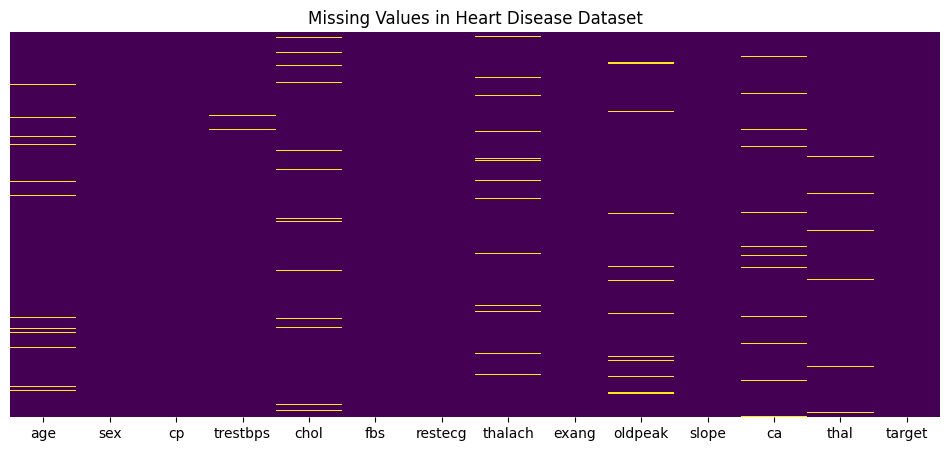


Number of Duplicate Rows: 1


In [ ]:

# Step 4: Check Missing Values and Duplicates

# Check missing values
print("Missing Values in Each Column:")
print(df.isnull().sum())

print("\nTotal Missing Values:", df.isnull().sum().sum())

# Visualize missing values
plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False, cmap="viridis")
plt.title("Missing Values in Heart Disease Dataset")
plt.show()

# Check duplicate records
print("\nNumber of Duplicate Rows:", df.duplicated().sum())


In [ ]:

# Step 5: Data Cleaning

# Remove duplicate records
df = df.drop_duplicates()

# Remove rows with missing target values
df = df.dropna(subset=["target"])

# Separate numerical input columns
numeric_cols = df.drop(columns=["target"]).columns

# Fill missing input values with their median
imputer = SimpleImputer(strategy="median")

df[numeric_cols] = imputer.fit_transform(df[numeric_cols])

# Check the cleaned dataset
print("Dataset shape after cleaning:", df.shape)

print("\nMissing values after cleaning:")
print(df.isnull().sum())

print("\nDuplicate rows after cleaning:", df.duplicated().sum())

print("\nFirst five cleaned records:")
display(df.head())


Dataset shape after cleaning: (3029, 14)

Missing values after cleaning:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate rows after cleaning: 0

First five cleaned records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,65.0,1.0,0.0,128.0,235.0,0.0,1.0,101.0,1.0,0.319263,1.0,1.0,3.0,1
1,58.0,1.0,0.0,128.0,259.0,0.0,0.0,130.0,1.0,3.000000,1.0,2.0,3.0,0
2,55.0,1.0,1.0,155.0,215.0,0.0,0.0,160.0,0.0,0.512287,2.0,1.0,2.0,0
3,40.0,1.0,0.0,110.0,167.0,0.0,0.0,114.0,1.0,2.000000,1.0,0.0,3.0,0
4,61.0,1.0,0.0,120.0,260.0,0.0,1.0,140.0,1.0,3.600000,1.0,1.0,3.0,0


,Feature,Outlier Count
0,age,9
1,sex,0
2,cp,0
3,trestbps,91
4,chol,65
5,fbs,461
6,restecg,0
7,thalach,25
8,exang,0
9,oldpeak,72


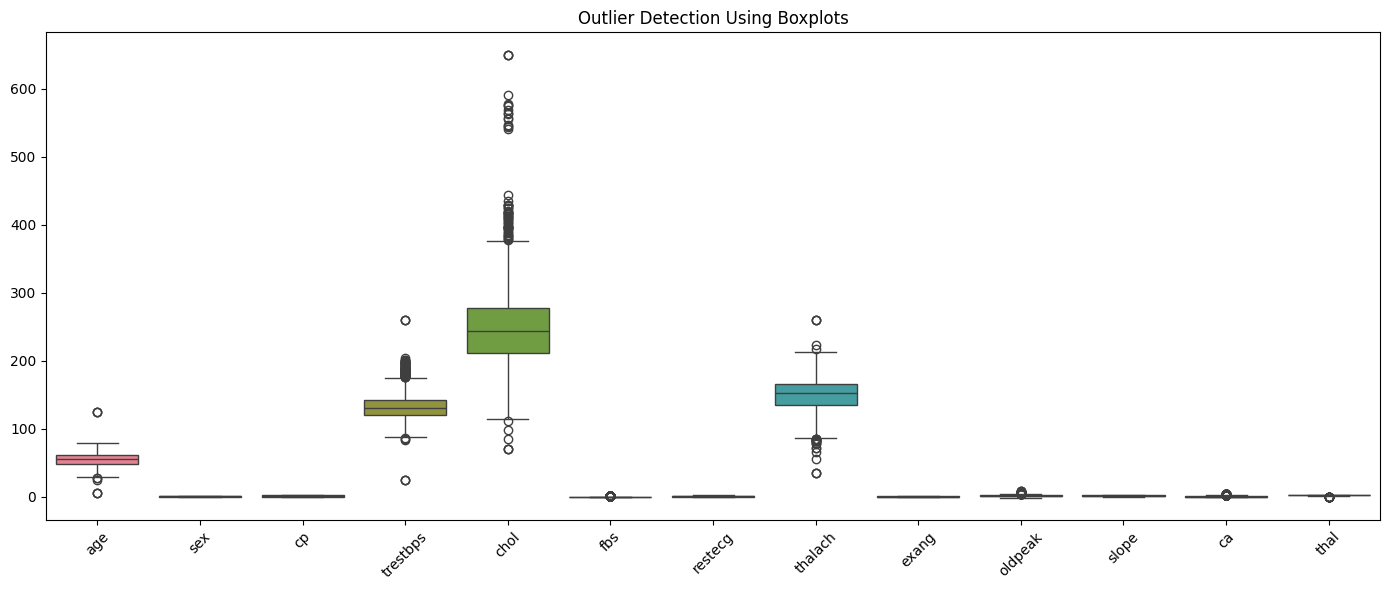

In [ ]:

# Step 6: Detect Outliers Using IQR

numeric_cols = df.drop(columns=["target"]).select_dtypes(
    include=np.number
).columns

outlier_counts = {}

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outlier_counts[col] = (
        ((df[col] < lower) | (df[col] > upper)).sum()
    )

outlier_df = pd.DataFrame(
    list(outlier_counts.items()),
    columns=["Feature", "Outlier Count"]
)

display(outlier_df)

# Visualize outliers
plt.figure(figsize=(14, 6))
sns.boxplot(data=df[numeric_cols])
plt.xticks(rotation=45)
plt.title("Outlier Detection Using Boxplots")
plt.tight_layout()
plt.show()


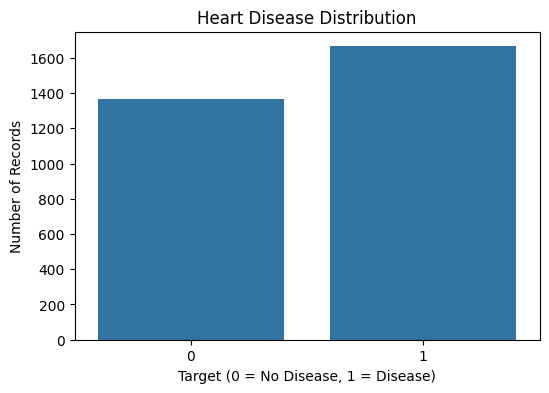

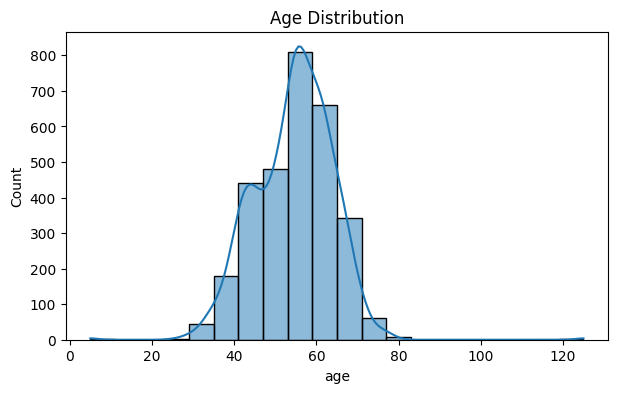

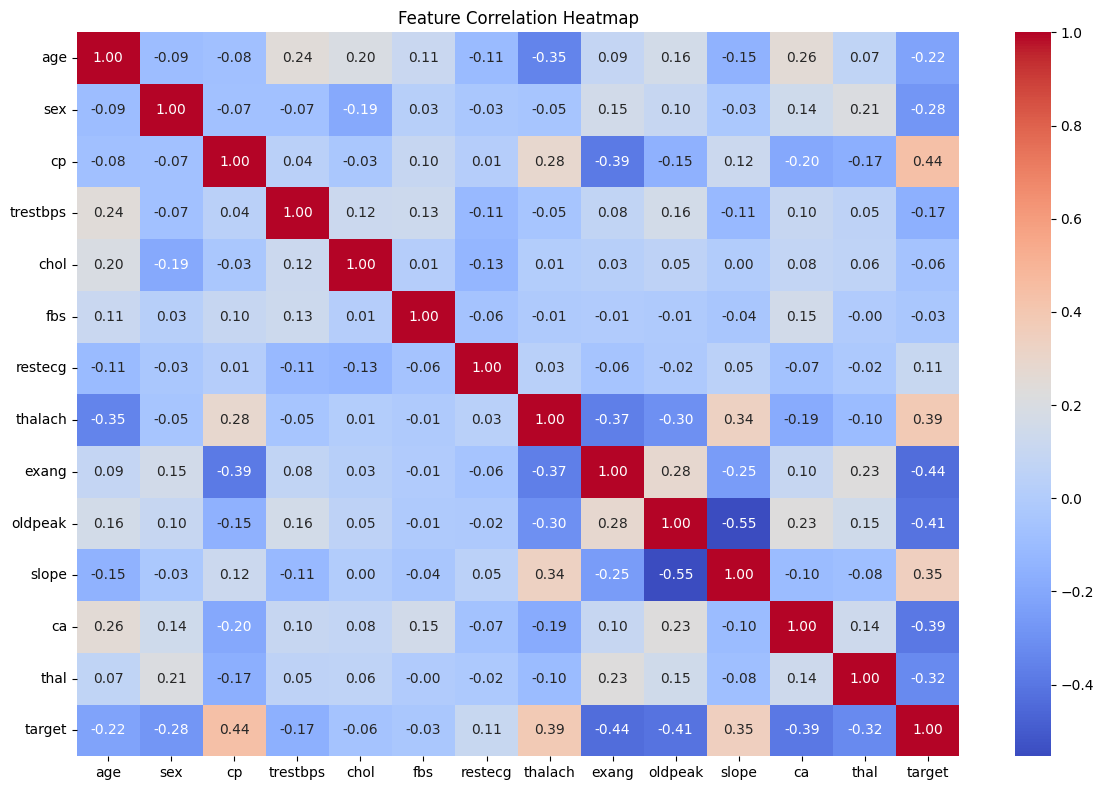

In [ ]:

# Step 7: Data Visualization

# 1. Target Distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="target")
plt.title("Heart Disease Distribution")
plt.xlabel("Target (0 = No Disease, 1 = Disease)")
plt.ylabel("Number of Records")
plt.show()

# 2. Age Distribution
plt.figure(figsize=(7, 4))
sns.histplot(data=df, x="age", bins=20, kde=True)
plt.title("Age Distribution")
plt.show()

# 3. Correlation Heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()


In [ ]:

# Step 8: Separate Features and Target

X = df.drop(columns=["target"])
y = df["target"].astype(int)

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("\nFeature Names:")
print(X.columns.tolist())


Input Features Shape: (3029, 13)
Target Shape: (3029,)

Feature Names:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [ ]:

# Step 9: Train-Test Split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)


Training Features: (2423, 13)
Testing Features: (606, 13)
Training Target: (2423,)
Testing Target: (606,)


In [ ]:

# Step 10: Remove Outliers Using IQR

numeric_cols = X.select_dtypes(include=np.number).columns

Q1 = X[numeric_cols].quantile(0.25)
Q3 = X[numeric_cols].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

# Identify rows containing outliers
outlier_mask = (
    (X[numeric_cols] < lower_limit) |
    (X[numeric_cols] > upper_limit)
).any(axis=1)

print("Rows containing outliers:", outlier_mask.sum())

# Remove outlier rows from both features and target
X = X.loc[~outlier_mask].reset_index(drop=True)
y = y.loc[~outlier_mask].reset_index(drop=True)

print("Shape after removing outliers:", X.shape)
print("Target shape after removing outliers:", y.shape)


Rows containing outliers: 789
Shape after removing outliers: (2240, 13)
Target shape after removing outliers: (2240,)


In [ ]:

# Step 11: Feature Scaling

scaler = StandardScaler()

# Fit on training data and transform both datasets
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("Scaled Training Data Shape:", X_train_scaled.shape)
print("Scaled Testing Data Shape:", X_test_scaled.shape)


Feature scaling completed successfully!
Scaled Training Data Shape: (2423, 13)
Scaled Testing Data Shape: (606, 13)


In [ ]:
# Step 12: Train SVM Models and Generate Predictions

# 1. Linear SVM
linear_svm = SVC(kernel='linear', random_state=42)
linear_svm.fit(X_train_scaled, y_train)
linear_pred = linear_svm.predict(X_test_scaled)

# 2. Polynomial SVM
poly_svm = SVC(kernel='poly', degree=3, random_state=42)
poly_svm.fit(X_train_scaled, y_train)
poly_pred = poly_svm.predict(X_test_scaled)

# 3. RBF SVM
rbf_svm = SVC(kernel='rbf', random_state=42)
rbf_svm.fit(X_train_scaled, y_train)
rbf_pred = rbf_svm.predict(X_test_scaled)

In [ ]:

# Step 13: Compare SVM Model Performance

results = []

models_predictions = {
    "Linear SVM": linear_pred,
    "Polynomial SVM": poly_pred,
    "RBF SVM": rbf_pred
}

for name, predictions in models_predictions.items():
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1-Score": f1_score(y_test, predictions, zero_division=0)
    })

results_df = pd.DataFrame(results)

results_df


,Model,Accuracy,Precision,Recall,F1-Score
0,Linear SVM,0.805281,0.782152,0.894895,0.834734
1,Polynomial SVM,0.950495,0.931624,0.981982,0.956140
2,RBF SVM,0.968647,0.956395,0.987988,0.971935


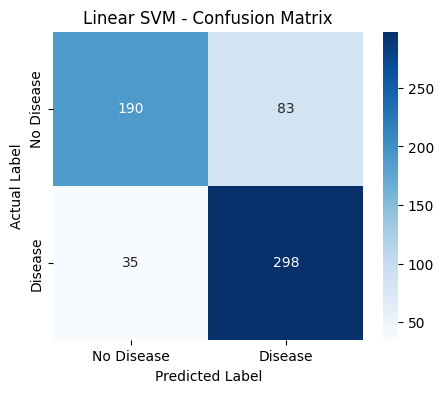

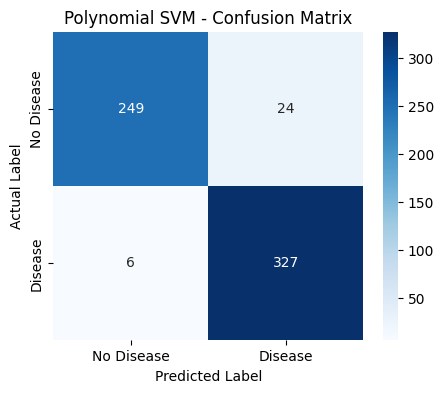

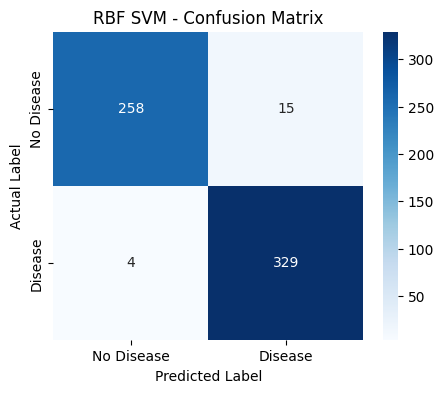

In [ ]:

# Step 14: Confusion Matrices

models_predictions = {
    "Linear SVM": linear_pred,
    "Polynomial SVM": poly_pred,
    "RBF SVM": rbf_pred
}

for name, predictions in models_predictions.items():

    cm = confusion_matrix(y_test, predictions)

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["No Disease", "Disease"],
        yticklabels=["No Disease", "Disease"]
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.show()


In [ ]:

# Step 15: Select the Best Model

models = {
    "Linear SVM": linear_svm,
    "Polynomial SVM": poly_svm,
    "RBF SVM": rbf_svm
}

best_model_name = results_df.loc[
    results_df["F1-Score"].idxmax(), "Model"
]

best_model = models[best_model_name]

print("Best Model:", best_model_name)
print(
    "Accuracy:",
    round(
        results_df.loc[
            results_df["Model"] == best_model_name,
            "Accuracy"
        ].iloc[0] * 100,
        2
    ),
    "%"
)

print(
    "F1-Score:",
    round(
        results_df.loc[
            results_df["Model"] == best_model_name,
            "F1-Score"
        ].iloc[0],
        4
    )
)


Best Model: RBF SVM
Accuracy: 96.86 %
F1-Score: 0.9719


In [ ]:

# Step 16: Save Model and Scaler

joblib.dump(best_model, "heart_disease_svm.pkl")
joblib.dump(scaler, "heart_disease_scaler.pkl")

print("Best model saved successfully!")
print("Scaler saved successfully!")
print("Selected Model:", best_model_name)


Best model saved successfully!
Scaler saved successfully!
Selected Model: RBF SVM


In [ ]:

# Step 17: Test the Best Model

sample_patient = X_test.iloc[[0]]
actual_result = y_test.iloc[0]

# Scale the sample using the existing scaler
sample_scaled = scaler.transform(sample_patient)

# Predict heart disease
prediction = best_model.predict(sample_scaled)[0]

print("Actual Result:", actual_result)
print("Predicted Result:", prediction)

if prediction == 1:
    print("Prediction: Heart Disease")
else:
    print("Prediction: No Heart Disease")


Actual Result: 0
Predicted Result: 0
Prediction: No Heart Disease


In [ ]:

# Step 18: Install Gradio

%pip install -q gradio

print("Gradio installed successfully!")


Gradio installed successfully!


In [27]:

# Step 19: Create the Prediction Website

import gradio as gr

def predict_heart_disease(
    age, sex, cp, trestbps, chol, fbs,
    restecg, thalach, exang, oldpeak,
    slope, ca, thal
):
    patient_data = pd.DataFrame([[
        age, sex, cp, trestbps, chol, fbs,
        restecg, thalach, exang, oldpeak,
        slope, ca, thal
    ]], columns=X.columns)

    # Scale patient data
    patient_scaled = scaler.transform(patient_data)

    # Predict using the selected model
    prediction = best_model.predict(patient_scaled)[0]

    if prediction == 1:
        return "Prediction: HEART DISEASE"
    else:
        return "Prediction: NO HEART DISEASE"


with gr.Blocks(title="Heart Disease Prediction") as demo:

    gr.Markdown("# Heart Disease Prediction Using SVM")
    gr.Markdown("Enter the patient details below.")

    with gr.Row():
        age = gr.Number(label="Age", value=55)
        sex = gr.Dropdown(
            choices=[0, 1], value=1, label="Sex"
        )
        cp = gr.Dropdown(
            choices=[0, 1, 2, 3], value=1,
            label="Chest Pain Type"
        )

    with gr.Row():
        trestbps = gr.Number(
            label="Resting Blood Pressure", value=140
        )
        chol = gr.Number(
            label="Cholesterol", value=250
        )
        fbs = gr.Dropdown(
            choices=[0, 1], value=0,
            label="Fasting Blood Sugar"
        )

    with gr.Row():
        restecg = gr.Dropdown(
            choices=[0, 1, 2], value=1,
            label="Resting ECG"
        )
        thalach = gr.Number(
            label="Maximum Heart Rate", value=150
        )
        exang = gr.Dropdown(
            choices=[0, 1], value=0,
            label="Exercise-Induced Angina"
        )

    with gr.Row():
        oldpeak = gr.Number(label="Oldpeak", value=1.0)
        slope = gr.Dropdown(
            choices=[0, 1, 2], value=1, label="Slope"
        )
        ca = gr.Dropdown(
            choices=[0, 1, 2, 3, 4], value=0,
            label="Number of Major Vessels"
        )

    thal = gr.Dropdown(
        choices=[0, 1, 2, 3], value=2,
        label="Thal"
    )

    predict_button = gr.Button(
        "Predict Heart Disease", variant="primary"
    )

    output = gr.Textbox(label="Prediction Result")

    predict_button.click(
        fn=predict_heart_disease,
        inputs=[
            age, sex, cp, trestbps, chol, fbs,
            restecg, thalach, exang, oldpeak,
            slope, ca, thal
        ],
        outputs=output
    )

demo.launch(share=True)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://165f413f00cecb269b.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
